In [48]:
%pip install numpy pandas matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/Student_Depression_Dataset.csv")

In [4]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [22]:
_categories = ["Gender", "Family_background", "Relationship_status", "Marital_status", "Living_style", "friend_circle", "Health_condition", "Home_division", "Depression"]
df[_categories] = df[_categories].astype("category")

In [23]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Gender               4464 non-null   category
 1   Age                  4464 non-null   int64   
 2   Family_background    4464 non-null   category
 3   Relationship_status  4464 non-null   category
 4   Marital_status       4464 non-null   category
 5   Living_style         4464 non-null   category
 6   Current_semester     4464 non-null   int64   
 7   CGPA                 4464 non-null   float64 
 8   friend_circle        4464 non-null   category
 9   Health_condition     4464 non-null   category
 10  Cost_without_study   4464 non-null   int64   
 11  Home_division        4464 non-null   category
 12  Depression           4464 non-null   category
dtypes: category(9), float64(1), int64(3)
memory usage: 179.2 KB


In [27]:
df.isna().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [28]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,4464,2,Female,2462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,4464.0,NaN,NaN,NaN,22.619176,2.02298,17.0,21.0,23.0,24.0,28.0
Family_background,4464,3,Middle class,2642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Relationship_status,4464,3,Single,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_status,4464,3,Unmarried,3619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Living_style,4464,2,Bachelor,2449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_semester,4464.0,NaN,NaN,NaN,5.40121,2.578476,0.0,3.0,5.0,7.0,13.0
CGPA,4464.0,NaN,NaN,NaN,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
friend_circle,4464,2,Yes,3215,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Health_condition,4464,4,Normal,1787,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
df.nunique()

Gender                    2
Age                      12
Family_background         3
Relationship_status       3
Marital_status            3
Living_style              2
Current_semester         14
CGPA                    169
friend_circle             2
Health_condition          4
Cost_without_study     1970
Home_division             8
Depression                2
dtype: int64

In [ ]:
df[_categories].apply(lambda col: col.unique().tolist())

Gender                                                    [Female, Male]
Family_background         [Middle class, Lower Middle class, Rich class]
Relationship_status             [Single, Complicated, In a Relationship]
Marital_status                           [Unmarried, Married, Separated]
Living_style                                          [Bachelor, Family]
friend_circle                                                  [Yes, No]
Health_condition                      [Critical, Abnormal, Good, Normal]
Home_division          [Chittagong, Dhaka, Rajshahi, Mymensingh, Bari...
Depression                                                     [Yes, No]
dtype: object

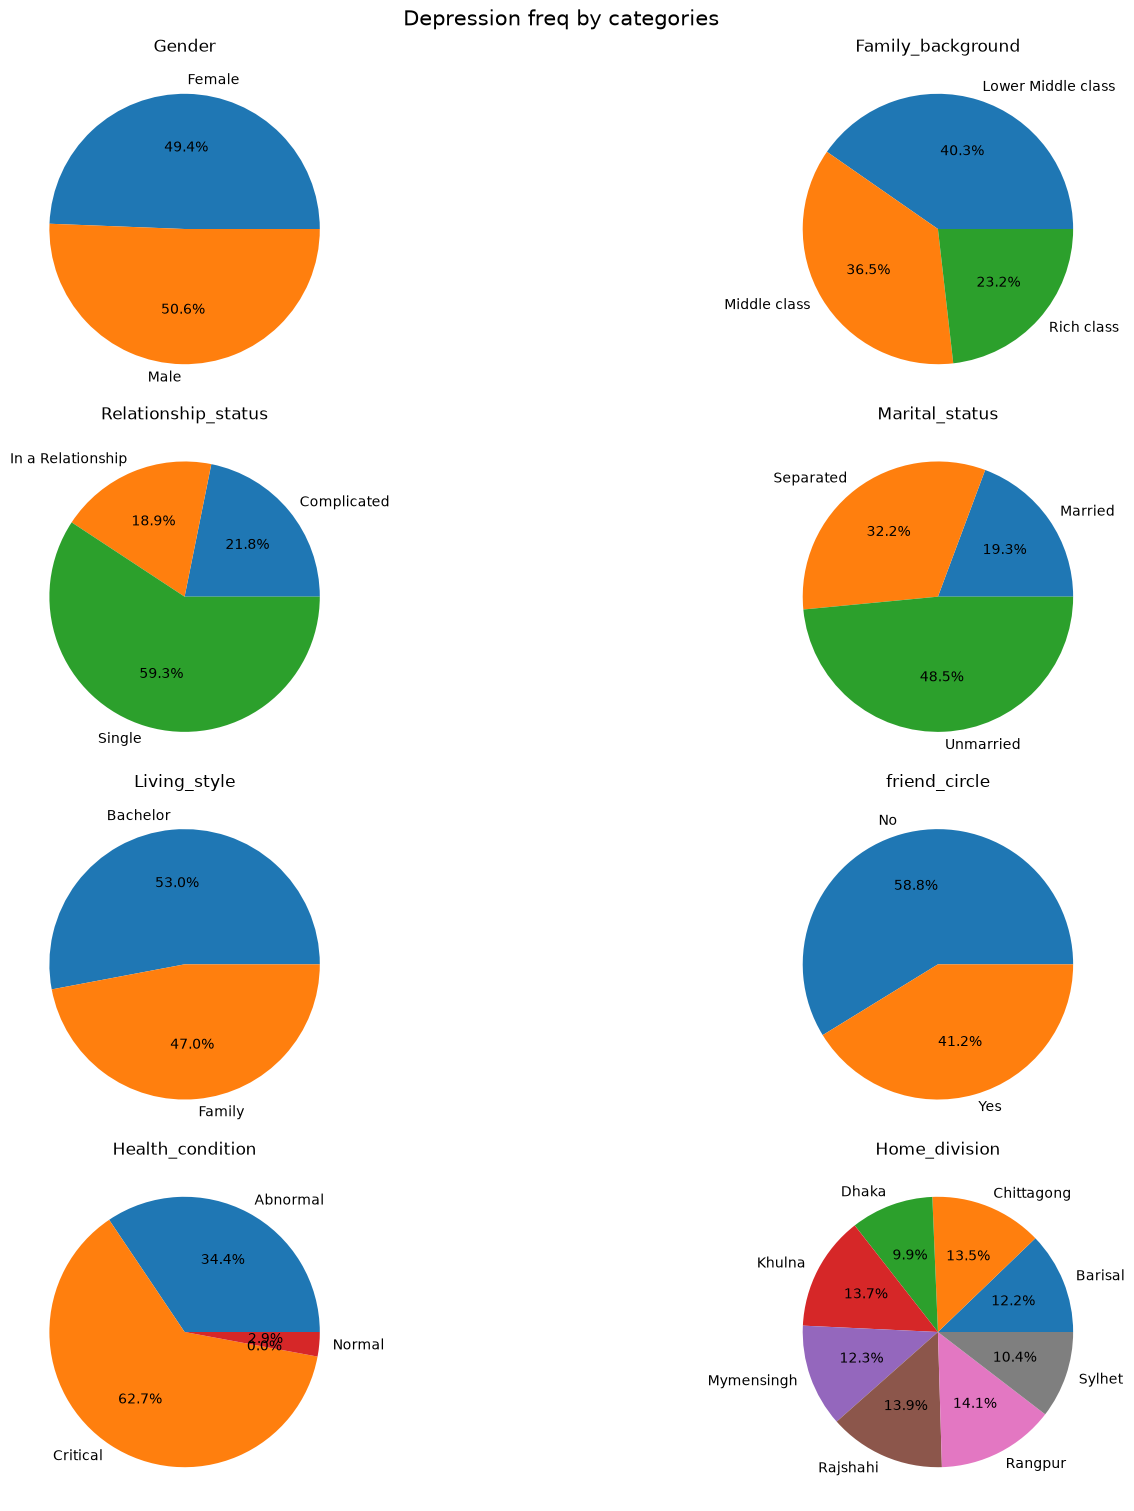

In [113]:
cat_stats = dict()

for category in _categories:
    cat_stats[category] = (
        df.assign(is_depressed=df["Depression"] == "Yes")
        .groupby(category)["is_depressed"]
        .mean()
        .mul(100)
    )

fig, axes = plt.subplots(4, 2, figsize=(15, 15), layout="constrained")
fig.suptitle("Depression freq by categories", fontsize=15)

for (category, stats), ax in zip(cat_stats.items(), axes.flat):
    stats.plot(ax=ax, kind="pie", autopct="%.1f%%",)
    ax.tick_params(axis="x", labelrotation=0)
    ax.set_title(category)
    ax.set_xlabel("")

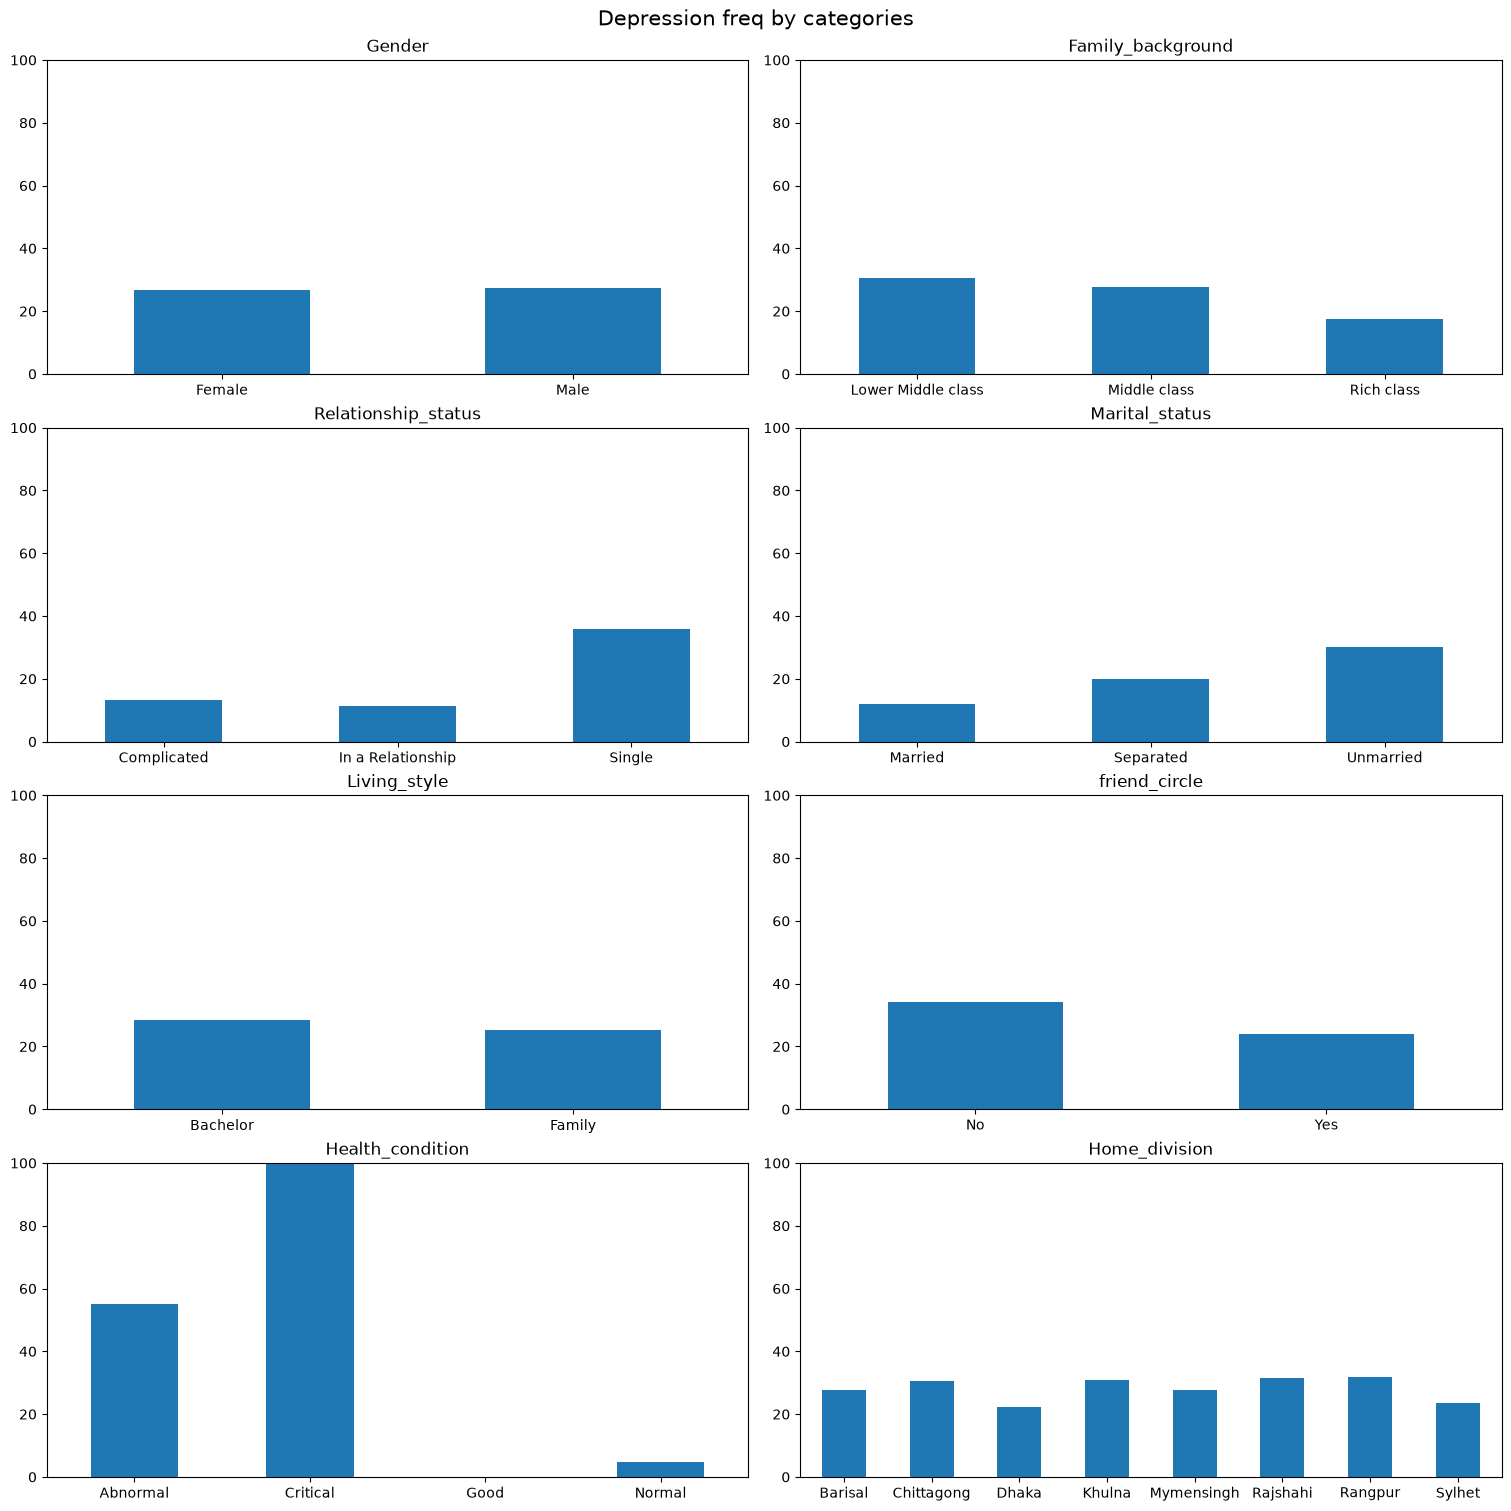

In [112]:
cat_stats = dict()

for category in _categories:
    cat_stats[category] = (
        df.assign(is_depressed=df["Depression"] == "Yes")
        .groupby(category)["is_depressed"]
        .mean()
        .mul(100)
    )

fig, axes = plt.subplots(4, 2, figsize=(15, 15), layout="constrained")
fig.suptitle("Depression freq by categories", fontsize=15)

for (category, stats), ax in zip(cat_stats.items(), axes.flat):
    stats.plot(ax=ax, kind="bar", ylim=(0, 100))
    ax.tick_params(axis="x", labelrotation=0)
    ax.set_title(category)
    ax.set_xlabel("")

<Axes: xlabel='Current_semester', ylabel='Percent'>

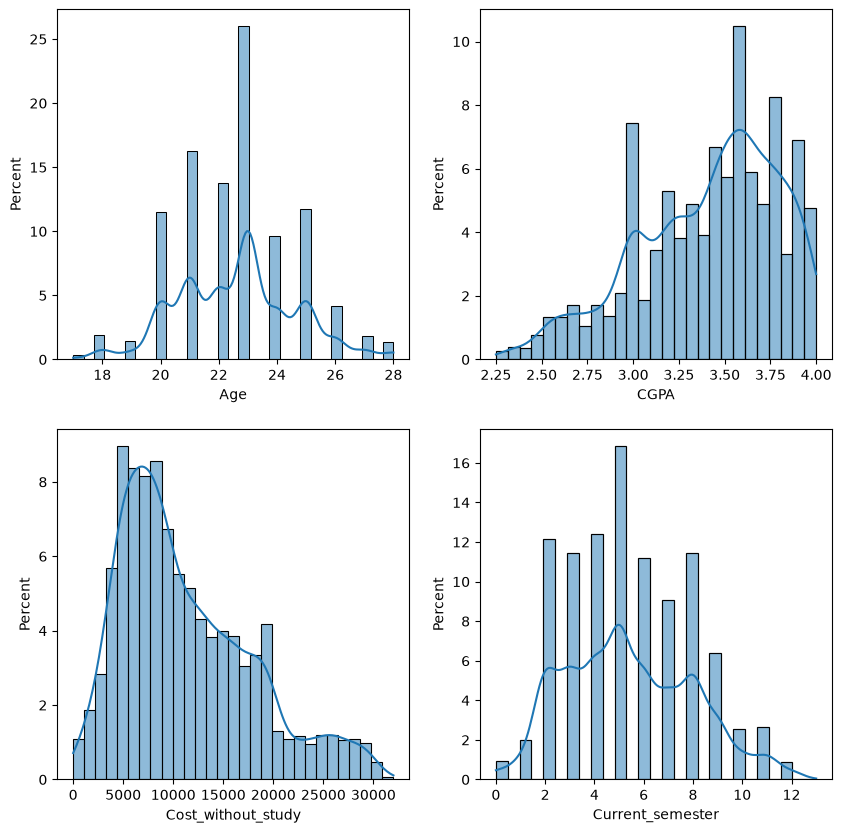

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
sns.histplot(ax=axes[0][0], data=df["Age"], stat="percent", kde=True)
sns.histplot(ax=axes[0][1], data=df["CGPA"], stat="percent", kde=True)
sns.histplot(ax=axes[1][0], data=df["Cost_without_study"], stat="percent", kde=True)
sns.histplot(ax=axes[1][1], data=df["Current_semester"], stat="percent", kde=True)

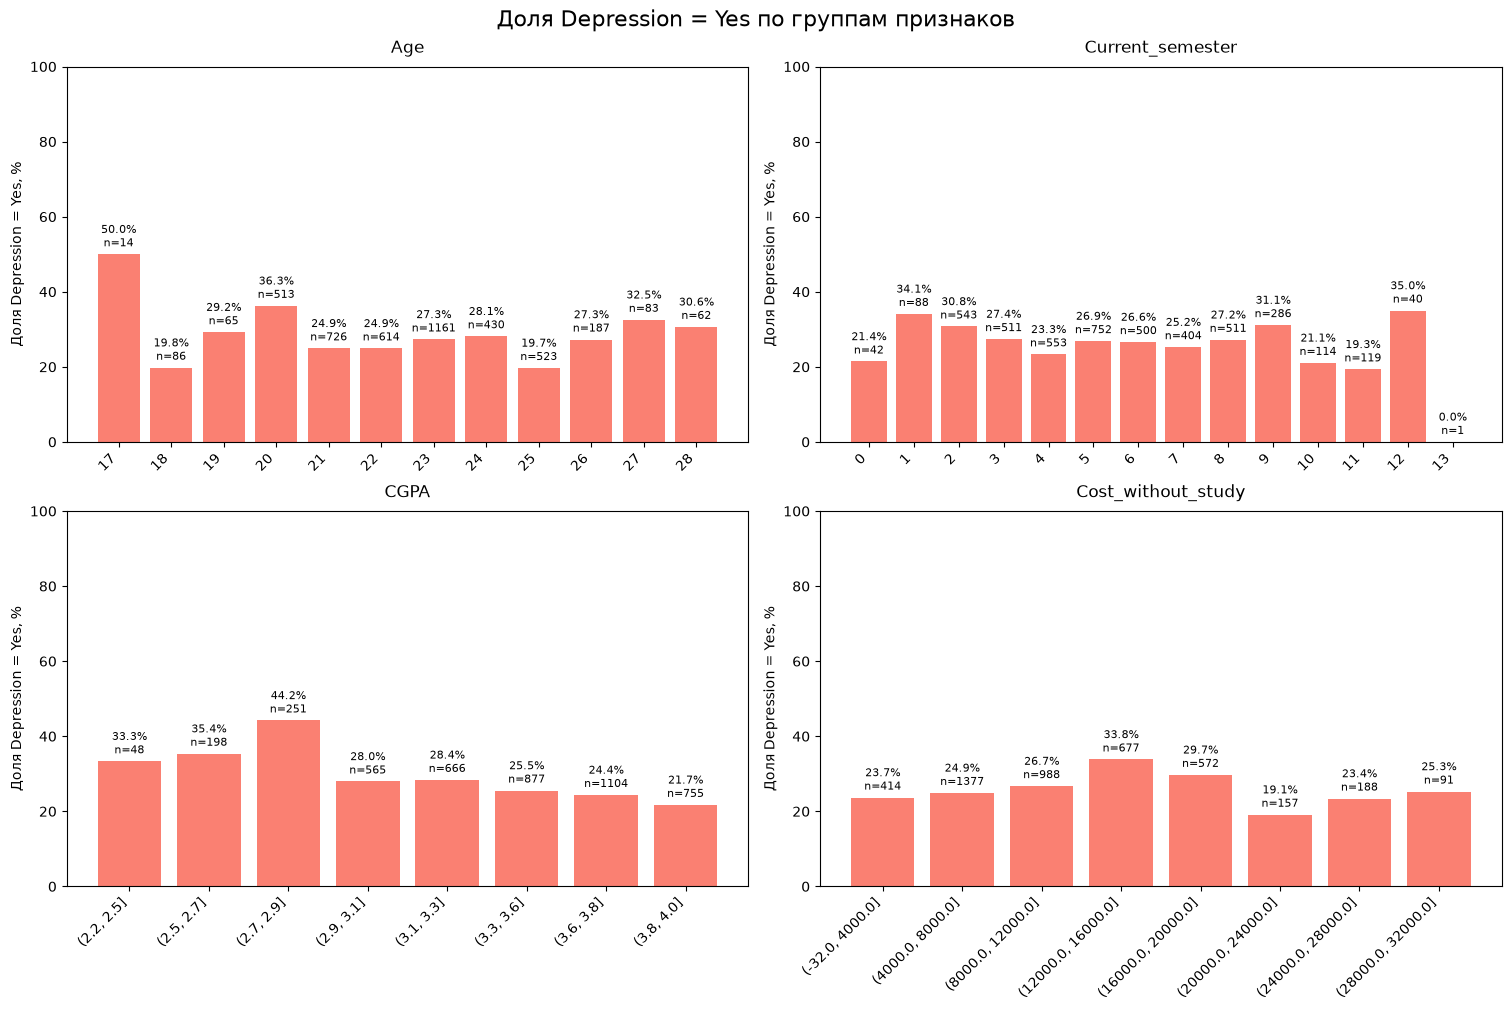

In [118]:
columns = ["Age", "Current_semester", "CGPA", "Cost_without_study"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
    layout="constrained",
)

for ax, col in zip(axes.flat, columns):
    # Непрерывные признаки разбиваем на 8 интервалов
    if col in ["Age", "Current_semester"]:
        groups = df[col]
    else:
        groups = pd.cut(df[col], bins=8, precision=1)

    stats = (
        df.assign(
            group=groups,
            is_depressed=df["Depression"]
                .map({"Yes": 1, "No": 0})
                .astype(float),
        )
        .groupby("group", observed=True)["is_depressed"]
        .agg(share="mean", n="count")
        .sort_index()
    )

    ax.bar(
        range(len(stats)),
        stats["share"] * 100,
        color="salmon",
    )

    ax.set_xticks(
        range(len(stats)),
        labels=[str(value) for value in stats.index],
    )

    ax.bar_label(
        ax.containers[0],
        labels=[
            f"{share:.1%}\nn={n}"
            for share, n in zip(stats["share"], stats["n"])
        ],
        padding=3,
        fontsize=8,
    )

    ax.set_title(col, pad=10)
    ax.set_ylabel("Доля Depression = Yes, %")
    ax.set_ylim(0, 100)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.suptitle("Доля Depression = Yes по группам признаков", fontsize=16)
plt.show()